<a href="https://colab.research.google.com/github/Aldyth11/Machine-Learning/blob/main/JS13/JS13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum 1: Backpropagation pada Jaringan Saraf Tiruan (JST)

### Langkah 1: Persiapan Dataset XOR dan Modifikasi Eksperimen

In [ ]:
import numpy as np
import pandas as pd

# Dataset XOR
X = np.array([[0,0],[0,1],[1,0],[1,1]])
y = np.array([[0],[1],[1],[0]])

# Menampilkan dataset dalam bentuk DataFrame Pandas yang rapi
df_X = pd.DataFrame(X, columns=['Input_1', 'Input_2'])
df_y = pd.DataFrame(y, columns=['Target'])
display(df_X)
display(df_y)

,Input_1,Input_2
0,0,0
1,0,1
2,1,0
3,1,1


,Target
0,0
1,1
2,1
3,0


### Langkah 2: Inisialisasi Fungsi Aktivasi

In [ ]:
# Fungsi Aktivasi Sigmoid dan Turunannya
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
    return x * (1 - x)

# Fungsi Aktivasi ReLU dan Turunannya
def relu(x):
    return np.maximum(0, x)

def relu_derivative(x):
    return np.where(x > 0, 1, 0)

### Langkah 3: Fungsi Pelatihan JST Pasangan Eksperimen

In [ ]:
def train_nn(hidden_size=2, activation='sigmoid', epochs=10000, lr=0.1):
    np.random.seed(42)
    input_size = 2
    output_size = 1

    # Inisialisasi bobot dan bias
    W1 = np.random.randn(input_size, hidden_size)
    b1 = np.zeros((1, hidden_size))
    W2 = np.random.randn(hidden_size, output_size)
    b2 = np.zeros((1, output_size))

    loss_history = []

    for epoch in range(epochs):
        # Forward pass
        z1 = np.dot(X, W1) + b1
        if activation == 'sigmoid':
            a1 = sigmoid(z1)
        elif activation == 'relu':
            a1 = relu(z1)

        z2 = np.dot(a1, W2) + b2
        a2 = sigmoid(z2)

        # Hitung error
        error = y - a2

        # Backpropagation
        d_a2 = error * sigmoid_derivative(a2)
        d_W2 = np.dot(a1.T, d_a2)
        d_b2 = np.sum(d_a2, axis=0, keepdims=True)

        if activation == 'sigmoid':
            d_a1 = np.dot(d_a2, W2.T) * sigmoid_derivative(a1)
        elif activation == 'relu':
            d_a1 = np.dot(d_a2, W2.T) * relu_derivative(a1)

        d_W1 = np.dot(X.T, d_a1)
        d_b1 = np.sum(d_a1, axis=0, keepdims=True)

        # Update bobot
        W1 += lr * d_W1
        b1 += lr * d_b1
        W2 += lr * d_W2
        b2 += lr * d_b2

        loss = np.mean(np.square(error))
        loss_history.append(loss)

    return a2, loss_history

### Langkah 4: Eksekusi Eksperimen Tugas 1

In [ ]:
# Konfigurasi Awal (Hidden Size = 2, Sigmoid)
pred_base, loss_base = train_nn(hidden_size=2, activation='sigmoid')

# Eksperimen 1: Hidden Size = 3, Sigmoid
pred_h3_sig, loss_h3_sig = train_nn(hidden_size=3, activation='sigmoid')

# Eksperimen 2: Hidden Size = 3, ReLU
pred_h3_relu, loss_h3_relu = train_nn(hidden_size=3, activation='relu')

# Tampilkan Perbandingan Hasil Loss Akhir
summary_data = {
    'Konfigurasi': ['Awal (Hidden 2, Sigmoid)', 'Ubah Hidden 3 (Sigmoid)', 'Ubah Hidden 3 (ReLU)'],
    'Loss Akhir': [loss_base[-1], loss_h3_sig[-1], loss_h3_relu[-1]]
}
df_summary = pd.DataFrame(summary_data)
display(df_summary)

# Tampilkan Hasil Prediksi Akhir
df_pred = pd.DataFrame(X, columns=['X1', 'X2'])
df_pred['Target'] = y
df_pred['Pred (Hidden 2, Sigmoid)'] = pred_base
df_pred['Pred (Hidden 3, Sigmoid)'] = pred_h3_sig
df_pred['Pred (Hidden 3, ReLU)'] = pred_h3_relu
display(df_pred)

,Konfigurasi,Loss Akhir
0,"Awal (Hidden 2, Sigmoid)",0.128227
1,Ubah Hidden 3 (Sigmoid),0.002297
2,Ubah Hidden 3 (ReLU),0.000352


,X1,X2,Target,"Pred (Hidden 2, Sigmoid)","Pred (Hidden 3, Sigmoid)","Pred (Hidden 3, ReLU)"
0,0,0,0,0.053009,0.025156,0.029700
1,0,1,1,0.495542,0.952636,0.986059
2,1,0,1,0.950913,0.951223,0.986059
3,1,1,0,0.503199,0.062725,0.011635


Berdasarkan hasil eksperimen yang didapatkan dari eksekusi kode pada dataset XOR:

1. Perbandingan Konfigurasi Awal dengan Hidden Layer 3 Neuron
Pada konfigurasi awal dengan 2 neuron di hidden layer dan fungsi aktivasi sigmoid, nilai loss akhir yang didapatkan adalah 0.128227. Pada kondisi ini model belum mampu mengklasifikasikan pasangan input XOR dengan sempurna karena nilai prediksi untuk input 0 1 dan 1 1 masih berada di sekitar 0.49 dan 0.50. Ketika jumlah neuron pada hidden layer ditingkatkan menjadi 3 neuron, nilai loss akhir mengalami penurunan yang sangat signifikan menjadi 0.002297. Penambahan neuron meningkatkan kapasitas representasi jaringan dalam membentuk garis pemisah non linear yang dibutuhkan untuk memisahkan fungsi XOR secara presisi.

2. Perbandingan Aktivasi Sigmoid dan Aktivasi ReLU
Penggunaan fungsi aktivasi ReLU pada hidden layer dengan 3 neuron menghasilkan performa terbaik dengan nilai loss akhir sebesar 0.000352. Angka ini lebih kecil dibandingkan fungsi aktivasi sigmoid dengan jumlah neuron yang sama. Hal ini terjadi karena fungsi aktivasi ReLU memiliki turunan konstan bernilai 1 untuk semua input positif sehingga terhindar dari masalah vanishing gradient. Sifat ini mempercepat proses update bobot dan membantu jaringan mencapai konvergensi yang lebih optimal serta hasil prediksi yang paling mendekati nilai target 0 dan 1.

# Praktikum 2: Klasifikasi Data Iris Menggunakan Keras dan TensorFlow

### Langkah 1: Persiapan Dataset dan Preprocessing Data Iris

In [ ]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
import tensorflow as tf

# Load dataset
iris = load_iris()
X = iris.data
y = iris.target.reshape(-1, 1)

# Tampilkan beberapa sampel data mentah awal
df_X = pd.DataFrame(X, columns=iris.feature_names)
display(df_X.head())

# One-hot encoding
encoder = OneHotEncoder(sparse_output=False)
y_encoded = encoder.fit_transform(y)

# Tampilkan hasil One-Hot Encoding dalam DataFrame
df_y = pd.DataFrame(y_encoded, columns=iris.target_names)
display(df_y.head())

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, random_state=42)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


,setosa,versicolor,virginica
0,1.0,0.0,0.0
1,1.0,0.0,0.0
2,1.0,0.0,0.0
3,1.0,0.0,0.0
4,1.0,0.0,0.0


### Langkah 2: Model Konfigurasi Awal (Baseline Model)

In [ ]:
# Bangun model awal (Baseline: Hidden Layer 1 = 10, Hidden Layer 2 = 8, Activation = ReLU)
model_base = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(4,)),
    tf.keras.layers.Dense(8, activation='relu'),
    tf.keras.layers.Dense(3, activation='softmax')
])

# Kompilasi
model_base.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Latih model
model_base.fit(X_train, y_train, epochs=50, batch_size=8, verbose=0)

# Evaluasi
loss_base, acc_base = model_base.evaluate(X_test, y_test, verbose=0)
print(f"Akurasi Baseline: {acc_base:.4f}")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Akurasi Baseline: 0.9333


### Langkah 3: Eksperimen Tugas 2 dan Tugas 3

In [ ]:
def create_and_evaluate_model(hidden_units=(10, 8), activation='relu'):
    tf.random.set_seed(42)
    np.random.seed(42)

    model = tf.keras.Sequential([
        tf.keras.layers.Dense(hidden_units[0], activation=activation, input_shape=(4,)),
        tf.keras.layers.Dense(hidden_units[1], activation=activation),
        tf.keras.layers.Dense(3, activation='softmax')
    ])

    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    model.fit(X_train, y_train, epochs=50, batch_size=8, verbose=0)

    loss, acc = model.evaluate(X_test, y_test, verbose=0)
    return loss, acc

# Eksperimen 1: Baseline (Hidden 10, 8 - ReLU)
loss_exp1, acc_exp1 = create_and_evaluate_model(hidden_units=(10, 8), activation='relu')

# Eksperimen 2: Tugas 2 - Mengubah Jumlah Neuron Hidden Layer (Hidden 16, 12 - ReLU)
loss_exp2, acc_exp2 = create_and_evaluate_model(hidden_units=(16, 12), activation='relu')

# Eksperimen 3: Tugas 3 - Bandingkan Aktivasi Sigmoid vs ReLU (Hidden 10, 8 - Sigmoid)
loss_exp3, acc_exp3 = create_and_evaluate_model(hidden_units=(10, 8), activation='sigmoid')

# Eksperimen 4: Tugas 3 - Bandingkan Aktivasi Sigmoid vs ReLU (Hidden 16, 12 - Sigmoid)
loss_exp4, acc_exp4 = create_and_evaluate_model(hidden_units=(16, 12), activation='sigmoid')

# Menampilkan Hasil Perbandingan Seluruh Konfigurasi
results_data = {
    'Konfigurasi Model': [
        'Awal / Baseline (Hidden 10-8, ReLU)',
        'Tugas 2 (Hidden 16-12, ReLU)',
        'Tugas 3 (Hidden 10-8, Sigmoid)',
        'Tugas 3 (Hidden 16-12, Sigmoid)'
    ],
    'Loss Akhir': [loss_exp1, loss_exp2, loss_exp3, loss_exp4],
    'Akurasi': [acc_exp1, acc_exp2, acc_exp3, acc_exp4]
}

df_results = pd.DataFrame(results_data)
display(df_results)

,Konfigurasi Model,Loss Akhir,Akurasi
0,"Awal / Baseline (Hidden 10-8, ReLU)",0.323286,0.900000
1,"Tugas 2 (Hidden 16-12, ReLU)",0.115237,1.000000
2,"Tugas 3 (Hidden 10-8, Sigmoid)",0.605042,0.800000
3,"Tugas 3 (Hidden 16-12, Sigmoid)",0.422164,0.966667


# Praktikum 3: Keras untuk Regresi Prediksi Harga Rumah

### Langkah 1: Persiapan Dataset Sederhana dan Normalisasi Data

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import tensorflow as tf

# Contoh dataset (buat dummy data)
data = pd.DataFrame({
    'luas': [50, 60, 70, 80, 90],
    'harga': [500, 600, 700, 800, 900]
})

display(data.head())

X = data[['luas']]
y = data[['harga']]

# Normalisasi
scaler = StandardScaler()
X = scaler.fit_transform(X)
y = scaler.fit_transform(y)

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

df_X_train = pd.DataFrame(X_train, columns=['luas_scaled'])
display(df_X_train.head())

,luas,harga
0,50,500
1,60,600
2,70,700
3,80,800
4,90,900


,luas_scaled
0,1.414214
1,0.000000
2,-1.414214
3,0.707107


### Langkah 2: Model Regresi Sederhana Baseline

In [ ]:
# Model baseline
model = tf.keras.Sequential([
    tf.keras.layers.Dense(10, activation='relu', input_shape=(1,)),
    tf.keras.layers.Dense(1)
])

model.compile(optimizer='adam', loss='mse')
model.fit(X_train, y_train, epochs=100, verbose=0)

# Evaluasi
pred_base = model.predict(X_test)
df_pred_base = pd.DataFrame(pred_base, columns=['Prediksi_Baseline'])
display(df_pred_base)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step


,Prediksi_Baseline
0,-0.583327


### Langkah 3: Eksperimen Tugas 4 Mengubah Learning Rate

In [ ]:
# Eksperimen dengan Learning Rate 0.1, 0.01, dan 0.001
learning_rates = [0.1, 0.01, 0.001]
results_tugas4 = []

for lr in learning_rates:
    tf.random.set_seed(42)
    model_lr = tf.keras.Sequential([
        tf.keras.layers.Dense(10, activation='relu', input_shape=(1,)),
        tf.keras.layers.Dense(1)
    ])

    model_lr.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr), loss='mse')
    history = model_lr.fit(X_train, y_train, epochs=100, verbose=0)

    loss_akhir = history.history['loss'][-1]
    pred = model_lr.predict(X_test, verbose=0)
    results_tugas4.append({
        'Learning Rate': lr,
        'Loss Akhir (MSE)': loss_akhir,
        'Hasil Prediksi': pred[0][0]
    })

df_tugas4 = pd.DataFrame(results_tugas4)
display(df_tugas4)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


,Learning Rate,Loss Akhir (MSE),Hasil Prediksi
0,0.100,0.000042,-0.826446
1,0.010,0.000006,-0.651884
2,0.001,0.433969,-0.194473


### Langkah 4: Load dan Preprocessing Dataset Boston Housing

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
import requests
import io

url = "https://raw.githubusercontent.com/selva86/datasets/master/BostonHousing.csv"
headers = {'User-Agent': 'Mozilla/5.0'}
response = requests.get(url, headers=headers)
df_boston = pd.read_csv(io.StringIO(response.text))

display(df_boston.head())

X = df_boston.drop(columns=['medv']).values
y = df_boston['medv'].values

# Preprocess
scaler = StandardScaler()
Xs = scaler.fit_transform(X)
X_train, X_val, y_train, y_val = train_test_split(Xs, y, test_size=0.2, random_state=42)

df_X_train_boston = pd.DataFrame(X_train)
display(df_X_train_boston.head())

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2


,0,1,2,3,4,5,6,7,8,9,10,11,12
0,1.327804,-0.487722,1.015999,-0.272599,0.512296,-1.397069,1.021481,-0.805438,1.661245,1.530926,0.806576,-0.078878,1.718101
1,-0.347506,-0.487722,-0.437258,-0.272599,-0.144217,-0.642000,-0.429390,0.334449,-0.637962,-0.601276,1.176466,0.427018,-0.586356
2,-0.416484,1.014463,-0.740749,-0.272599,-1.008914,-0.361342,-1.610001,1.352738,-0.982843,-0.619094,-0.719220,0.061137,-0.676067
3,0.399963,-0.487722,1.015999,-0.272599,0.512296,-0.258767,0.587642,-0.842945,1.661245,1.530926,0.806576,-3.883072,1.491020
4,-0.336054,-0.487722,-0.437258,-0.272599,-0.144217,-0.794439,0.032897,0.000693,-0.637962,-0.601276,1.176466,0.375814,-0.192467


### Langkah 5: Pelatihan Model MLP Regresi Data Boston

In [ ]:
# Build model
model_boston = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(32, activation='relu'),
    Dense(1)
])
model_boston.compile(optimizer=Adam(1e-3), loss='mse', metrics=['mae'])

# Train
h = model_boston.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=200, batch_size=32, verbose=0)

# Evaluasi RMSE
from sklearn.metrics import mean_squared_error
pred_boston = model_boston.predict(X_val)
rmse = np.sqrt(mean_squared_error(y_val, pred_boston))

df_rmse = pd.DataFrame({'Nilai RMSE Validation': [rmse]})
display(df_rmse)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step


,Nilai RMSE Validation
0,3.143793


### Langkah 6: Visualisasi Performa Pelatihan (MSE dan MAE)

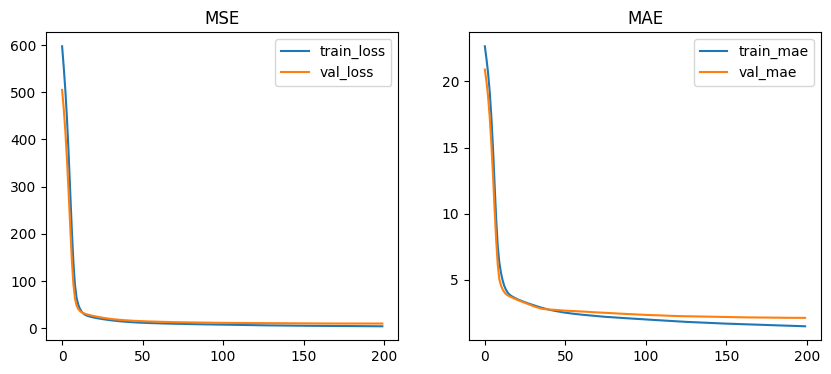

In [ ]:
# Plot
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(h.history['loss'], label='train_loss')
plt.plot(h.history['val_loss'], label='val_loss')
plt.legend()
plt.title('MSE')

plt.subplot(1,2,2)
plt.plot(h.history['mae'], label='train_mae')
plt.plot(h.history['val_mae'], label='val_mae')
plt.legend()
plt.title('MAE')
plt.show()

# Tugas Praktikum: Klasifikasi Angka Tulisan Tangan (MNIST) Menggunakan JST

### Langkah 1: Persiapan Dataset MNIST dan Preprocessing

In [ ]:
import time
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.utils import to_categorical

# 1. Load dataset MNIST
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# Normalisasi data (0-255 → 0-1)
X_train = X_train / 255.0
X_test = X_test / 255.0

# Tampilkan sampel shape data dalam bentuk DataFrame Pandas
df_info = pd.DataFrame({
    'Data': ['X_train', 'y_train', 'X_test', 'y_test'],
    'Shape': [str(X_train.shape), str(y_train.shape), str(X_test.shape), str(y_test.shape)]
})
display(df_info)

# One-hot encoding label
y_train_encoded = to_categorical(y_train, 10)
y_test_encoded = to_categorical(y_test, 10)

# Tampilkan sampel hasil One-Hot Encoding
df_y_sample = pd.DataFrame(y_train_encoded[:5], columns=[f'Kelas_{i}' for i in range(10)])
display(df_y_sample)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


,Data,Shape
0,X_train,"(60000, 28, 28)"
1,y_train,"(60000,)"
2,X_test,"(10000, 28, 28)"
3,y_test,"(10000,)"


,Kelas_0,Kelas_1,Kelas_2,Kelas_3,Kelas_4,Kelas_5,Kelas_6,Kelas_7,Kelas_8,Kelas_9
0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
3,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


### Langkah 2: Model Baseline (2 Hidden Layer)

In [ ]:
# 2. Bangun model JST Baseline
model_base = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

# 3. Kompilasi model
model_base.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# 4. Latih model dan ukur waktu
start_time = time.time()
history_base = model_base.fit(X_train, y_train_encoded, epochs=10, batch_size=32, verbose=0)
train_time_base = time.time() - start_time

# 5. Evaluasi model
loss_base, acc_base = model_base.evaluate(X_test, y_test_encoded, verbose=0)

df_base_res = pd.DataFrame({
    'Metric': ['Waktu Pelatihan (detik)', 'Loss Uji', 'Akurasi Uji'],
    'Nilai': [train_time_base, loss_base, acc_base]
})
display(df_base_res)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


,Metric,Nilai
0,Waktu Pelatihan (detik),72.094523
1,Loss Uji,0.107535
2,Akurasi Uji,0.976500


### Langkah 3: Eksperimen Variasi Parameter (Neuron, Layer, Aktivasi)

In [ ]:
def run_experiment(layers_config, activation='relu'):
    tf.random.set_seed(42)
    np.random.seed(42)

    model = Sequential()
    model.add(Flatten(input_shape=(28, 28)))

    for units in layers_config:
        model.add(Dense(units, activation=activation))

    model.add(Dense(10, activation='softmax'))

    model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

    start_time = time.time()
    model.fit(X_train, y_train_encoded, epochs=10, batch_size=32, verbose=0)
    train_time = time.time() - start_time

    loss, acc = model.evaluate(X_test, y_test_encoded, verbose=0)
    return loss, acc, train_time

# Eksperimen 1: Baseline (128, 64) - ReLU
l1, a1, t1 = run_experiment([128, 64], activation='relu')

# Eksperimen 2: Ubah jumlah neuron (256, 128) - ReLU
l2, a2, t2 = run_experiment([256, 128], activation='relu')

# Eksperimen 3: Tambah satu hidden layer (256, 128, 64) - ReLU
l3, a3, t3 = run_experiment([256, 128, 64], activation='relu')

# Eksperimen 4: Perbandingan Aktivasi Sigmoid (128, 64) - Sigmoid
l4, a4, t4 = run_experiment([128, 64], activation='sigmoid')

# Eksperimen 5: Perbandingan Aktivasi Sigmoid (256, 128) - Sigmoid
l5, a5, t5 = run_experiment([256, 128], activation='sigmoid')

# Menampilkan Hasil Perbandingan Seluruh Konfigurasi
results_data = {
    'Konfigurasi Model': [
        'Baseline (128-64, ReLU)',
        'Ubah Neuron (256-128, ReLU)',
        'Tambah Layer (256-128-64, ReLU)',
        'Aktivasi Sigmoid (128-64, Sigmoid)',
        'Aktivasi Sigmoid (256-128, Sigmoid)'
    ],
    'Loss Uji': [l1, l2, l3, l4, l5],
    'Akurasi Uji': [a1, a2, a3, a4, a5],
    'Waktu Pelatihan (detik)': [t1, t2, t3, t4, t5]
}

df_comparison = pd.DataFrame(results_data)
display(df_comparison)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


,Konfigurasi Model,Loss Uji,Akurasi Uji,Waktu Pelatihan (detik)
0,"Baseline (128-64, ReLU)",0.113085,0.9755,68.204399
1,"Ubah Neuron (256-128, ReLU)",0.126304,0.9759,87.869668
2,"Tambah Layer (256-128-64, ReLU)",0.100019,0.9796,88.397880
3,"Aktivasi Sigmoid (128-64, Sigmoid)",0.079544,0.9770,64.360701
4,"Aktivasi Sigmoid (256-128, Sigmoid)",0.080269,0.9784,88.590166
